# Reto 1 · Exploración y calidad de datos

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: entender la base de clientes y **auditar la calidad del dato** antes de segmentar. Cada decisión de
limpieza se toma con datos, comparando alternativas y midiendo su efecto, porque una mala decisión aquí se
arrastra a los clusters.

1. Carga, tipos y **granularidad** (¿qué es una fila?)
2. Exclusión justificada de **metadatos e identificadores**
3. **Valores nulos**: cuánto falta, **por qué** falta (mecanismo) y **qué hacer** en cada columna
4. **Inconsistencias** y detalles del dato
5. **Estadísticas descriptivas** y **distribuciones**, separando por país y por nivel (cliente / vehículo)
6. Resumen de hallazgos y conclusiones

**Dos niveles de análisis.** El fichero tiene una fila por **relación cliente–vehículo**. Los atributos de cliente
(edad, consentimientos, código postal…) se repiten en cada vehículo del cliente. Por eso, todo lo que describe
**clientes** se calcula con **una fila por cliente** (si no, los clientes con muchos vehículos pesarían más), y lo
que describe **vehículos** con todas las filas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
AZUL, AZUL_CLARO = "#00677F", "#9cc3cc"

DATA = "datos_reto_mercedes_benz_malackathon.csv"  # CSV en la raíz del repositorio
# zipcode se lee como texto: mezcla números y textos (p. ej. "CH-6340") y no es una cantidad
df = pd.read_csv(DATA, dtype={"zipcode": "string"}, low_memory=False)
df.shape

(302850, 39)

## 1. Estructura y granularidad

In [2]:
df.head(3).T

,0,1,2
Unnamed: 0,0,1,2
client_id,000144e39c02702f821f69beeb7036f40cf8505051050f...,000144e39c02702f821f69beeb7036f40cf8505051050f...,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fab...
vehicle_id,db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba6...,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...,716e4f639ce69defa3b9ce202848cdca612814e7d0dc47...
age_range,35-44,35-44,25-34
gender_derived,female,female,male
model_series,177,206,213
vehicle_type,A 180 d,C 200 d,AMG E 63 S 4MATIC+
model_class,A-Class,C-Class,E-Class
product_group,P,P,P
engine_concept,NaN,NaN,COMBUSTION


In [3]:
tipos = pd.DataFrame({"tipo": df.dtypes.astype(str), "valores distintos": df.nunique(),
                      "% nulos": df.isna().mean().mul(100).round(1), "ejemplo": df.iloc[1]})
tipos

,tipo,valores distintos,% nulos,ejemplo
Unnamed: 0,int64,302850,0.00,1
client_id,str,173456,0.00,000144e39c02702f821f69beeb7036f40cf8505051050f...
vehicle_id,str,244519,0.00,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...
age_range,str,6,0.00,35-44
gender_derived,str,2,11.20,female
model_series,int64,88,0.00,206
vehicle_type,str,1436,0.30,C 200 d
model_class,str,42,1.10,C-Class
product_group,str,4,0.00,P
engine_concept,str,4,44.40,NaN


Ajustes de tipo necesarios: `date_of_first_registration` llega como texto (se convierte a fecha);
`trip_distance_mode` y `speed_mode` llegan como texto porque a veces contienen **varios valores separados por
comas** (modas empatadas); `model_series` es un código y no una cantidad.

In [4]:
n_rows, n_clients, n_vehicles = len(df), df["client_id"].nunique(), df["vehicle_id"].nunique()
pd.Series({
    "filas (relaciones cliente-vehículo)": n_rows,
    "clientes únicos": n_clients,
    "vehículos únicos": n_vehicles,
    "pares (cliente, vehículo) duplicados": df.duplicated(["client_id", "vehicle_id"]).sum(),
    "filas duplicadas completas (sin el índice)": df.drop(columns="Unnamed: 0").duplicated().sum(),
    "¿'Unnamed: 0' es 0..n-1?": int((df["Unnamed: 0"].to_numpy() == np.arange(n_rows)).all()),
})

filas (relaciones cliente-vehículo)           302850
clientes únicos                               173456
vehículos únicos                              244519
pares (cliente, vehículo) duplicados               0
filas duplicadas completas (sin el índice)         0
¿'Unnamed: 0' es 0..n-1?                           1
dtype: int64

No hay duplicados. Hay **más relaciones que vehículos**: un mismo vehículo puede estar vinculado a varios
clientes (propietario, conductor, usuario temporal…).

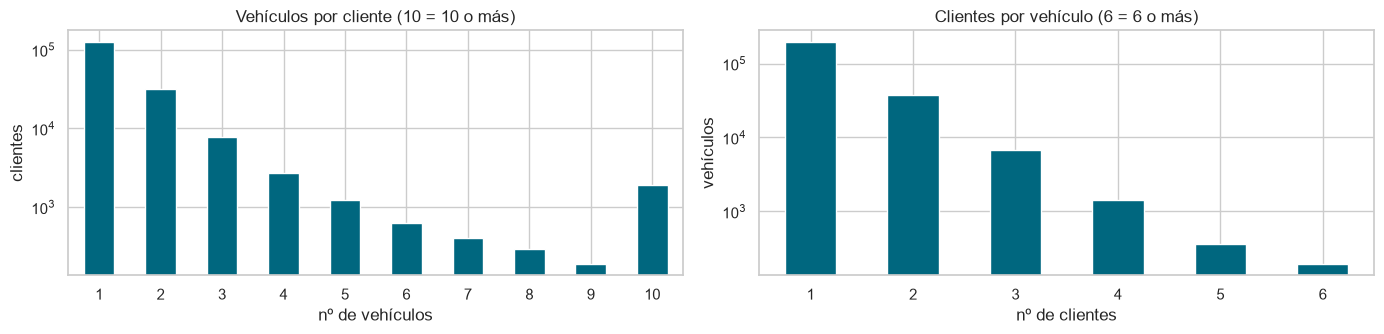

mediana de vehículos por cliente                 1.00
clientes con >10 vehículos (perfil flota)    1,706.00
  % de clientes                                  1.00
  % de filas que acumulan                       20.00
  máximo de vehículos de un cliente            561.00
vehículos vinculados a >1 cliente           46,648.00
  máximo de clientes de un vehículo             36.00
dtype: float64

In [5]:
veh_por_cliente = df.groupby("client_id").size()
cli_por_veh = df.groupby("vehicle_id")["client_id"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
veh_por_cliente.clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[0], color=AZUL, rot=0)
axes[0].set(title="Vehículos por cliente (10 = 10 o más)", xlabel="nº de vehículos", ylabel="clientes", yscale="log")
cli_por_veh.clip(upper=6).value_counts().sort_index().plot.bar(ax=axes[1], color=AZUL, rot=0)
axes[1].set(title="Clientes por vehículo (6 = 6 o más)", xlabel="nº de clientes", ylabel="vehículos", yscale="log")
plt.tight_layout()
plt.show()

grandes = veh_por_cliente[veh_por_cliente > 10]
compartidos = cli_por_veh[cli_por_veh > 1]
pd.Series({
    "mediana de vehículos por cliente": veh_por_cliente.median(),
    "clientes con >10 vehículos (perfil flota)": len(grandes),
    "  % de clientes": len(grandes) / n_clients * 100,
    "  % de filas que acumulan": grandes.sum() / n_rows * 100,
    "  máximo de vehículos de un cliente": veh_por_cliente.max(),
    "vehículos vinculados a >1 cliente": len(compartidos),
    "  máximo de clientes de un vehículo": cli_por_veh.max(),
}).round(1)

In [6]:
# ¿Qué atributos son de cliente, de vehículo o de la relación? Se comprueba si son constantes dentro de cada grupo
atrib_cliente = ["age_range", "gender_derived", "country_code", "months_as_mb_customer", "currently_connected_vehicles",
                 "finance_leasing_status", "consent_phone_communication_channel", "consent_epost_communication_channel",
                 "consent_post_communication_channel", "zipcode", "purchasing_power_per_household_eur"]
atrib_vehiculo = ["model_class", "vehicle_type", "engine_concept", "fuel_type", "date_of_first_registration",
                  "trip_distance_average", "speed_average", "workshop_visits_warranty_goodwill"]
var_cli = (df.groupby("client_id")[atrib_cliente].nunique(dropna=False) > 1).sum()
var_veh = (df[df["vehicle_id"].isin(compartidos.index)].groupby("vehicle_id")[atrib_vehiculo].nunique(dropna=False) > 1).sum()
display(var_cli.rename("clientes con >1 valor").to_frame())
var_veh.rename("vehículos compartidos con >1 valor").to_frame()

,clientes con >1 valor
age_range,0
gender_derived,0
country_code,0
months_as_mb_customer,0
currently_connected_vehicles,0
finance_leasing_status,0
consent_phone_communication_channel,0
consent_epost_communication_channel,0
consent_post_communication_channel,0
zipcode,0


,vehículos compartidos con >1 valor
model_class,0
vehicle_type,0
engine_concept,0
fuel_type,0
date_of_first_registration,0
trip_distance_average,24993
speed_average,24883
workshop_visits_warranty_goodwill,29292


- Los **atributos de cliente** son 100 % constantes entre sus filas: la agregación a una fila por cliente no tiene
  conflictos.
- Los atributos técnicos del vehículo (modelo, motor, matriculación) coinciden entre los clientes que lo comparten.
  En cambio, la **telemetría** y las **visitas al taller** cambian: son datos de la **relación** (cómo conduce *ese*
  cliente *ese* coche), no del vehículo. Por eso se agregarán por cliente y no por vehículo.

In [7]:
# Roles: qué significa cada uno y si la relación sigue activa
roles = pd.crosstab(df["role"], df["is_current_vehicle"], margins=True)
roles["% activa"] = roles[True] / roles["All"] * 100
roles

is_current_vehicle,False,True,All,% activa
role,,,,
DRIVER,4972,549,5521,9.94
LEGACY,6094,5220,11314,46.14
OWNER,102782,161636,264418,61.13
TEMP_USER,3795,171,3966,4.31
USER,5041,12590,17631,71.41
All,122684,180166,302850,59.49


## 2. Columnas de metadatos e identificadores

| Columna | Decisión | Motivo |
|---|---|---|
| `Unnamed: 0` | **Excluir** | Índice exportado (es exactamente 0…n-1); no es información |
| `client_id` | **Excluir como feature** | Hash identificador. Solo como clave para agregar por cliente |
| `vehicle_id` | **Excluir** | Hash identificador. Solo para contar vehículos |
| `zipcode` | **Excluir como feature** | Identificador geográfico (4.610 valores); su información útil está en las variables socioeconómicas del CP |
| `model_series` | **Excluir** | Código interno; `model_class` resume la misma información de forma legible |
| `vehicle_type` | **Excluir como feature** | 1.436 denominaciones comerciales; se usa solo para **deducir** gama y electrificación cuando faltan |
| `trip_distance_mode`, `speed_mode` | **Excluir** | Texto con modas empatadas ("3,7.5") y valores de tramo de histograma (ver apartado 4) |
| `trip_distance_median`, `speed_median` | **Excluir** | Solo 12-13 valores posibles: son **límites de tramo**, no medianas reales |
| `trip_distance_all_counter`, `speed_all_counter` | **Excluir como feature** | Contadores técnicos de mediciones, no comportamiento del cliente |
| `fuel_type` | **Excluir** | Redundante con `engine_concept` y con más nulos (59 % vs 44 %) |

## 3. Valores nulos

### 3.1 ¿Cuánto falta?

El porcentaje de nulos cambia según el nivel. A nivel **cliente**, un atributo de vehículo cuenta como nulo solo
si falta en **todos** sus vehículos.

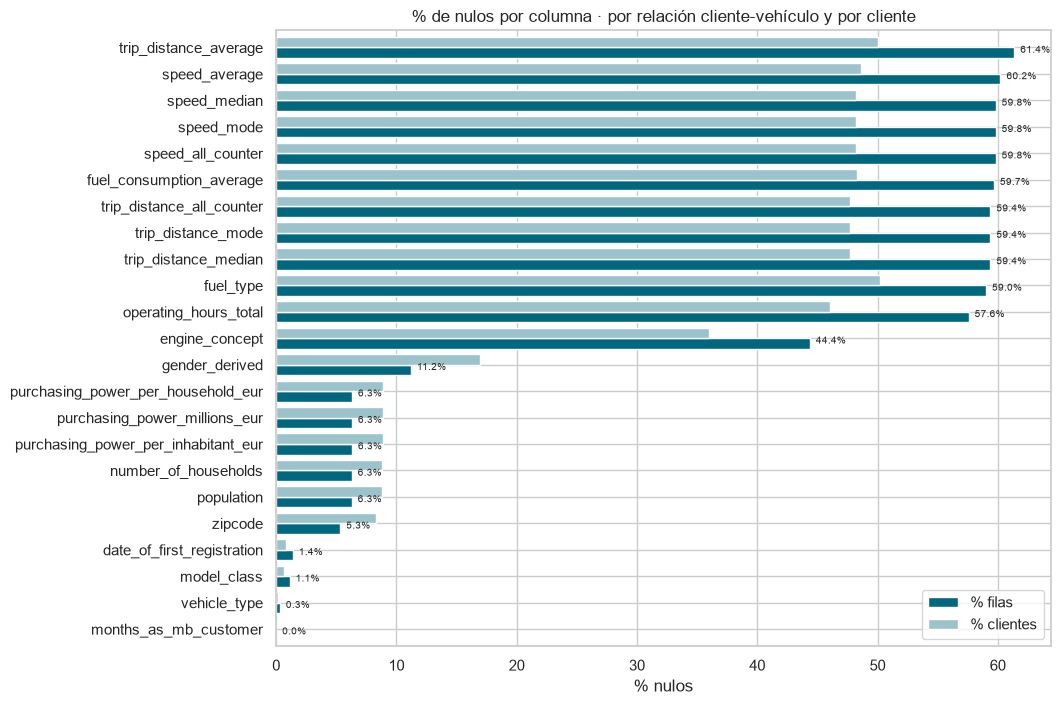

,% filas,% clientes
trip_distance_average,61.40,50.10
speed_average,60.20,48.60
speed_median,59.80,48.20
speed_all_counter,59.80,48.20
speed_mode,59.80,48.20
fuel_consumption_average,59.70,48.30
trip_distance_median,59.40,47.70
trip_distance_all_counter,59.40,47.70
trip_distance_mode,59.40,47.70
fuel_type,59.00,50.20


In [8]:
nul_filas = df.isna().mean().mul(100)
nul_cli = df.isna().groupby(df["client_id"]).all().mean().mul(100)
nulos = pd.DataFrame({"% filas": nul_filas, "% clientes": nul_cli})
nulos = nulos[nulos["% filas"] > 0].sort_values("% filas")
ax = nulos.plot.barh(figsize=(10, 8), color=[AZUL, AZUL_CLARO], width=.8)
for i, v in enumerate(nulos["% filas"]):
    ax.text(v + .5, i - .2, f"{v:.1f}%", fontsize=7)
ax.set(title="% de nulos por columna · por relación cliente-vehículo y por cliente", xlabel="% nulos")
plt.show()
nulos.sort_values("% filas", ascending=False).round(1)

Hay **tres bloques** de columnas con nulos: telemetría (~60 % de filas), motorización (44-59 %) y
socioeconómicos (6 %). Fuera de ellos, solo `gender_derived` (11 % de filas, 17 % de clientes) y nulos residuales
(< 1,5 %). El nivel importa: los socioeconómicos faltan en el 6,3 % de las filas pero en el **8,9 % de los
clientes**, porque los clientes sin dato tienen, de media, menos vehículos. Medir solo por filas subestimaría el problema.

### 3.2 ¿Los nulos van juntos?

Mapa de presencia (azul = nulo) sobre una muestra y correlación entre los indicadores de nulo. Columnas cuyo nulo
está muy correlacionado faltan **a la vez**, por una misma causa.

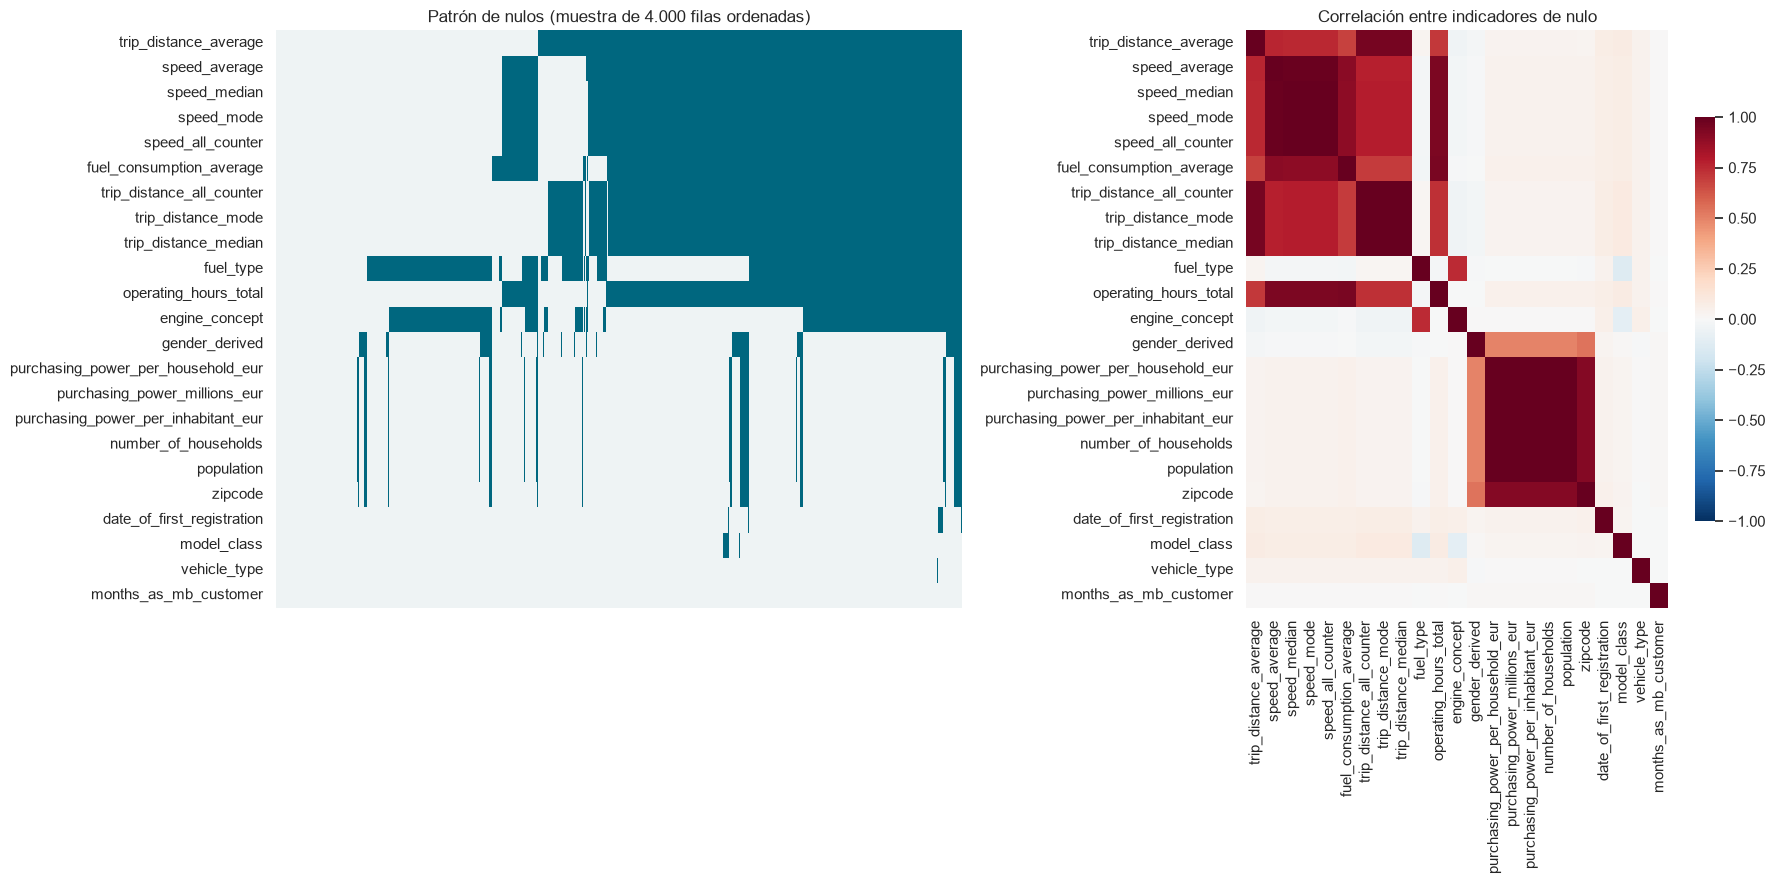

In [9]:
cols_con_nulos = nulos.index.tolist()[::-1]
muestra = df.sample(4000, random_state=0)[cols_con_nulos].isna()
fig, axes = plt.subplots(1, 2, figsize=(18, 9), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(muestra.sort_values(cols_con_nulos).T, cbar=False, cmap=["#eef3f4", AZUL], xticklabels=False, ax=axes[0])
axes[0].set(title="Patrón de nulos (muestra de 4.000 filas ordenadas)")
sns.heatmap(df[cols_con_nulos].isna().corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": .7})
axes[1].set(title="Correlación entre indicadores de nulo")
plt.tight_layout()
plt.show()

In [10]:
cols_tel = ["trip_distance_average", "trip_distance_mode", "trip_distance_median", "trip_distance_all_counter",
            "operating_hours_total", "fuel_consumption_average", "speed_average", "speed_mode", "speed_median",
            "speed_all_counter"]
patrones = df[cols_tel].isna().value_counts().head(8).rename("filas").to_frame()
patrones["% filas"] = patrones["filas"] / n_rows * 100
patrones

filas  \
trip_distance_average trip_distance_mode trip_distance_median trip_distance_all_counter operating_hours_total fuel_consumption_average speed_average speed_mode speed_median speed_all_counter           
True                  True               True                 True                      True                  True                     True          True       True         True               156819   
False                 False              False                False                     False                 False                    False         False      False        False               96680   
                                                                                        True                  True                     True          True       True         True                15587   
True                  True               True                 True                      False                 False                    False         False      False        False               14151   
                                                                                                                                       True          True       True         True                 7009   
False                 False              False                False                     False                 True                     False         False      False        False                4449   
True                  False              False                False                     False                 False                    False         False      False        False                3276   
                                                                                                              True                     False         False      False        False                1113   

                                                                                                                                                                                                % filas  
trip_distance_average trip_distance_mode trip_distance_median trip_distance_all_counter operating_hours_total fuel_consumption_average speed_average speed_mode speed_median speed_all_counter           
True                  True               True                 True                      True                  True                     True          True       True         True                 51.78  
False                 False              False                False                     False                 False                    False         False      False        False                31.92  
                                                                                        True                  True                     True          True       True         True                  5.15  
True                  True               True                 True                      False                 False                    False         False      False        False                 4.67  
                                                                                                                                       True          True       True         True                  2.31  
False                 False              False                False                     False                 True                     False         False      False        False                 1.47  
True                  False              False                False                     False                 False                    False         False      False        False                 1.08  
                                                                                                              True                     False         False      False        False                 0.37

La telemetría falta casi siempre **en bloque** (todas las columnas a la vez). Hay patrones parciales: filas con
horas de funcionamiento pero sin trayectos, y filas con todo salvo el consumo (propio de vehículos enchufables).

### 3.3 ¿Por qué falta? Nulos por subgrupo

El tratamiento correcto depende del **mecanismo**:
- **Aleatorio** (MCAR): el nulo no depende de nada. Imputar o eliminar apenas sesga.
- **Depende de otras variables observadas** (MAR): el nulo se concentra en ciertos grupos. Eliminar esas filas
  **sesga la muestra**, e imputar debe hacerse **dentro del grupo**.
- **Estructural** (no aplica / no se mide): el dato no existe para ese caso. **No se debe imputar**: se
  inventaría un valor que no tiene sentido.

Para distinguirlos, comparamos el % de nulos entre subgrupos.

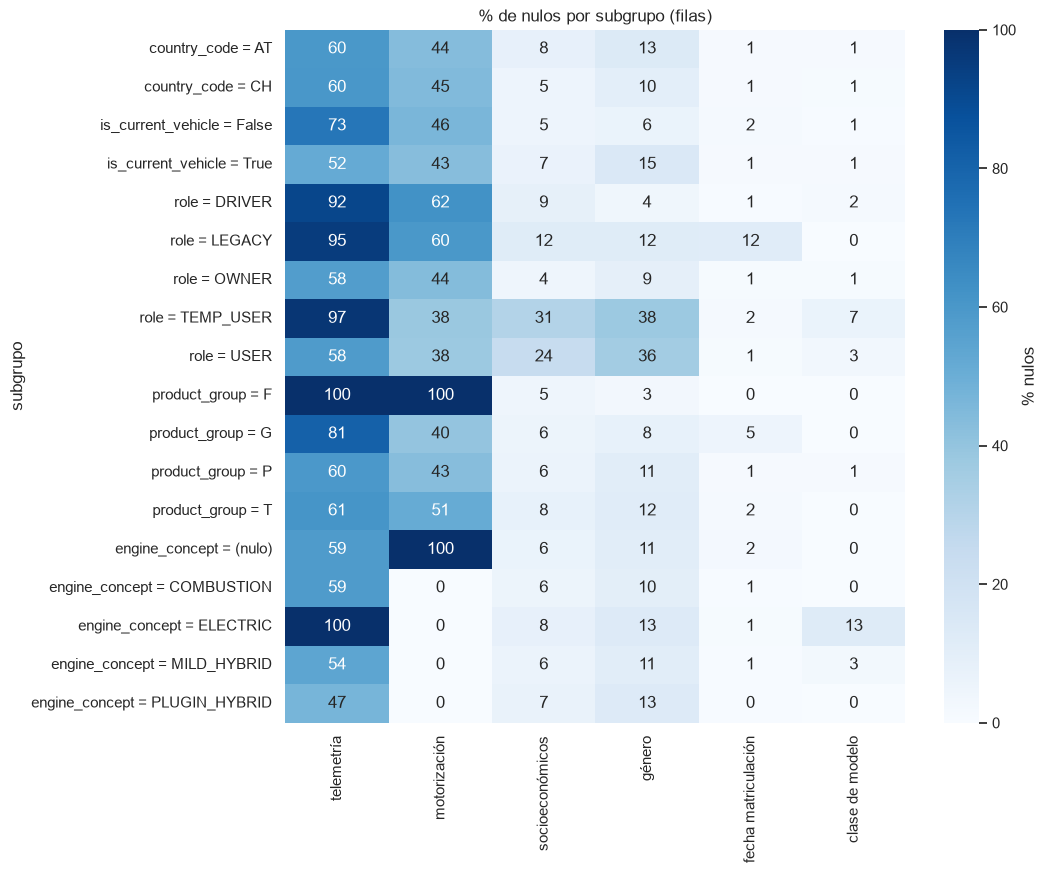

In [11]:
reg = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
FECHA_REF = reg.max()  # fecha de referencia del extracto: la matriculación más reciente
df["anio_matriculacion"] = reg.dt.year
df["engine_concept_"] = df["engine_concept"].fillna("(nulo)")
cols_mec = {"speed_average": "telemetría", "engine_concept": "motorización", "purchasing_power_per_household_eur": "socioeconómicos",
            "gender_derived": "género", "date_of_first_registration": "fecha matriculación", "model_class": "clase de modelo"}
filas = []
for var in ["country_code", "is_current_vehicle", "role", "product_group", "engine_concept_"]:
    for valor, g in df.groupby(var):
        fila = {"subgrupo": f"{var.rstrip('_')} = {valor}", "filas": len(g)}
        fila.update({nombre: g[c].isna().mean() * 100 for c, nombre in cols_mec.items()})
        filas.append(fila)
tabla_mec = pd.DataFrame(filas).set_index("subgrupo")
plt.figure(figsize=(10, 9))
sns.heatmap(tabla_mec.drop(columns="filas"), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% nulos"})
plt.title("% de nulos por subgrupo (filas)")
plt.show()

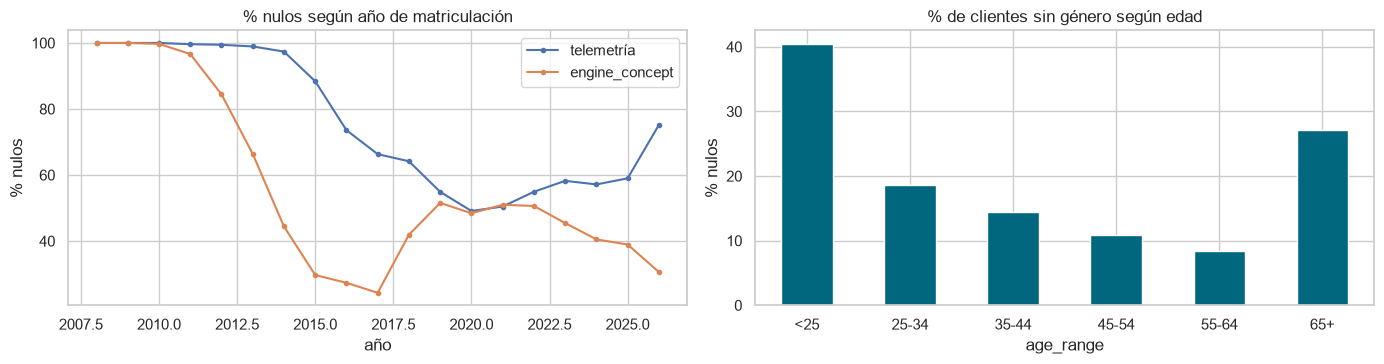

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
(df.groupby("anio_matriculacion")[["speed_average", "engine_concept"]].apply(lambda g: g.isna().mean() * 100)
   .loc[2008:].rename(columns={"speed_average": "telemetría", "engine_concept": "engine_concept"})
   .plot(ax=axes[0], marker="o", ms=3, title="% nulos según año de matriculación", ylabel="% nulos", xlabel="año"))
clientes = df.drop_duplicates("client_id")
orden_edad = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
(clientes.groupby("age_range")["gender_derived"].apply(lambda s: s.isna().mean() * 100).reindex(orden_edad)
   .plot.bar(ax=axes[1], color=AZUL, rot=0, title="% de clientes sin género según edad", ylabel="% nulos"))
plt.tight_layout()
plt.show()

**Lectura por bloque:**

- **Telemetría → estructural.** Falta en el **100 % de los eléctricos** (el sistema no la recoge para BEV), en el
  **92-97 % de los roles no propietarios** (DRIVER, LEGACY, TEMP_USER), en casi todos los coches **anteriores a 2016**
  (sin hardware conectado) y en el 100 % de los smart. No falta "porque sí": **no existe** para esos casos. Imputarla
  inventaría conducción; y usar "tiene telemetría" como rasgo del cliente mezclaría *eléctrico*, *coche antiguo* y
  *no propietario*. → **Ni imputar ni usar en el modelo**; solo para describir clusters, con esa advertencia.
- **Motorización → sistema de origen.** El % de nulos varía con el año de forma irregular (84 % en 2012, 24 % en
  2017, ~50 % en 2019-2022) y no por país: depende de qué sistema registró el vehículo. → Categoría `UNKNOWN` y
  deducción por nombre comercial (`EQ…`, `… e`, `… de`, `electric`).
- **Socioeconómicos → depende del país y del rol**: 8 % en AT frente a 5 % en CH, y 24-31 % en relaciones USER y
  TEMP_USER frente al 4 % de OWNER (clientes de los que no consta dirección). Además hay códigos postales sin cruce.
  → Imputar **dentro de cada país**. No eliminar: se perderían sobre todo los usuarios no propietarios.
- **Género → depende de la edad y del país**: falta en el 40 % de los menores de 25 y el 27 % de los mayores de 65,
  frente al 9-11 % de 45-64; y más en AT (21 %) que en CH (15 %). → **No eliminar** (sesgaría la edad) ni imputar con
  la moda (convertiría a 1 de cada 6 clientes en "hombre" sin base). También falta mucho más en USER y TEMP_USER
  (36-38 %). Categoría `unknown`.
- **Fecha de matriculación → depende del rol**: falta en el 12 % de las relaciones LEGACY (vehículos antiguos
  heredados de otro sistema) y en el 5 % de los G-Class; en el resto, ~1 %. El volumen total es pequeño (1,4 %).
- **Clase de modelo → modelos nuevos**: falta en el 13 % de los eléctricos (gamas EQ recientes sin clase asignada).
  Se deduce del nombre comercial.

### 3.4 ¿Media, mediana o eliminar? El efecto de cada opción

**Poder adquisitivo.** Comparamos imputar con la media global, la mediana global o la mediana de cada país.

,mean,median,min,max,skew
country_code,,,,,
AT,"66,639.14","66,938.25","45,087.34","113,527.18",0.21
CH,"125,616.37","116,082.37","57,361.82","342,497.95",2.32
global,"106,347.13","103,738.42","45,087.34","342,497.95",1.67


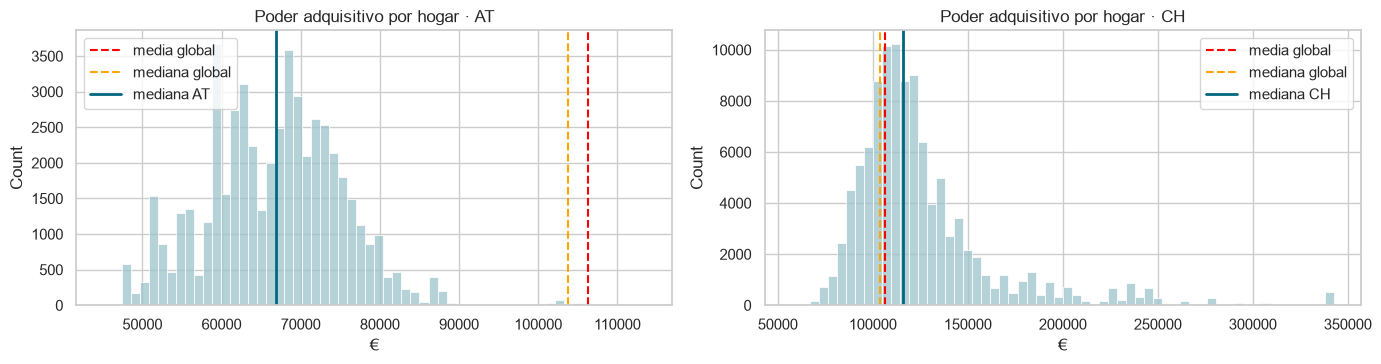

Un cliente austriaco imputado con la media global quedaría por encima del 88 % de los austriacos.


In [13]:
pp = "purchasing_power_per_household_eur"
estad = clientes.groupby("country_code")[pp].agg(["mean", "median", "min", "max", "skew"])
estad.loc["global"] = [clientes[pp].mean(), clientes[pp].median(), clientes[pp].min(), clientes[pp].max(), clientes[pp].skew()]
display(estad.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, pais in zip(axes, ["AT", "CH"]):
    s = clientes.loc[clientes["country_code"] == pais, pp].dropna()
    sns.histplot(s, bins=60, ax=ax, color=AZUL_CLARO)
    ax.axvline(estad.loc["global", "mean"], color="red", ls="--", label="media global")
    ax.axvline(estad.loc["global", "median"], color="orange", ls="--", label="mediana global")
    ax.axvline(estad.loc[pais, "median"], color=AZUL, lw=2, label=f"mediana {pais}")
    ax.set(title=f"Poder adquisitivo por hogar · {pais}", xlabel="€")
    ax.legend()
plt.tight_layout()
plt.show()
p_at = (clientes.loc[clientes["country_code"] == "AT", pp] < estad.loc["global", "mean"]).mean() * 100
print(f"Un cliente austriaco imputado con la media global quedaría por encima del {p_at:.0f} % de los austriacos.")

- La **media global** (106 k€) y la **mediana global** (104 k€) caen en la cola alta de Austria: un cliente austriaco
  sin dato pasaría a ser de los más ricos de su país. **Imputación global descartada.**
- Dentro de CH la distribución es **muy asimétrica** (asimetría 2,3): la media (126 k€) está inflada por zonas muy
  ricas y no representa al cliente típico. **Media descartada.**
- **Decisión: mediana de su país.** En el Reto 2 la variable se usa como percentil dentro del país, y el nulo pasa a
  0,5, que es exactamente la mediana del país.

**¿Y si eliminamos los clientes con nulos?** Simulamos eliminar los clientes sin género o sin poder adquisitivo.

In [14]:
completos = clientes.dropna(subset=["gender_derived", pp])
perdida = 1 - len(completos) / len(clientes)
comp = pd.DataFrame({
    "todos": clientes["age_range"].value_counts(normalize=True),
    "sin nulos": completos["age_range"].value_counts(normalize=True),
}).reindex(orden_edad).mul(100)
comp.loc["AT (país)"] = [(clientes["country_code"] == "AT").mean() * 100, (completos["country_code"] == "AT").mean() * 100]
comp["diferencia (pp)"] = comp["sin nulos"] - comp["todos"]
print(f"Se perderían {len(clientes) - len(completos):,} clientes ({perdida:.1%})")
comp.round(1)

Se perderían 32,272 clientes (18.6%)


,todos,sin nulos,diferencia (pp)
age_range,,,
<25,4.70,3.40,-1.40
25-34,15.50,15.20,-0.30
35-44,18.90,19.50,0.70
45-54,21.00,22.70,1.70
55-64,19.60,21.80,2.10
65+,20.20,17.40,-2.80
AT (país),33.80,31.80,-2.00


Eliminar perdería el **18,6 % de los clientes** y además **cambiaría el perfil** de la base: menos jóvenes (<25),
menos mayores (65+) y menos austriacos. Los segmentos resultantes describirían una población que no es la real.
**Eliminar filas queda descartado** para todas las columnas; los nulos se tratan con imputación por grupo o con
categorías explícitas.

### 3.5 Decisión columna a columna

| Columna | % filas | % clientes | Mecanismo | Opciones valoradas | Decisión | Consecuencia |
|---|---|---|---|---|---|---|
| Telemetría (10 columnas) | 57-61 | 46-50 | Estructural: BEV, roles no propietarios, coches < 2016 | Imputar mediana · eliminar filas · flag "tiene telemetría" | **Ni imputar ni modelar**. Solo para perfilar, con advertencia | Se pierde la conducción como rasgo, pero se evita inventar datos o penalizar a los eléctricos |
| `fuel_type` | 59 | 50 | Sistema de origen; redundante | Imputar · usar | **Excluir** (usar `engine_concept`) | Ninguna: `engine_concept` contiene la misma información con menos nulos |
| `engine_concept` | 44 | 36 | Sistema de origen (varía por año, no por país) | Moda (COMBUSTION) · eliminar · `UNKNOWN` + deducción por nombre | **Deducir electrificación por nombre**; resto `UNKNOWN` | Algún híbrido sin sufijo puede quedar como no electrificado (subestimación leve) |
| `gender_derived` | 11 | 17 | Depende de edad y país | Eliminar · moda ("male") · `unknown` | **Categoría `unknown`**; fuera del modelo | Sin sesgo de edad; el género solo describe |
| Socioeconómicos (5 columnas) | 6,3 | 8,9 | Depende del país + CP sin cruce | Media / mediana global · eliminar · mediana del país | **Mediana del país** (percentil 0,5) y una sola variable | Un 9 % de clientes queda en el centro de su país: atenúa algo la variable, sin desplazar a nadie |
| `zipcode` | 5,3 | 8,3 | Igual que socioeconómicos | — | **Excluir** (identificador) | — |
| `date_of_first_registration` | 1,4 | 0,8 | Depende del rol (12 % en LEGACY) y algo más en G-Class | Eliminar · mediana global · mediana por gama | **Antigüedad del vehículo: mediana** (si el cliente tiene otro vehículo con fecha, se usa ese) | Afecta a 1.348 clientes (0,8 %): efecto despreciable |
| `model_class` | 1,1 | 0,7 | Modelos nuevos (GLC 400, GLB 350, CLA…) | `UNKNOWN` · deducir | **Deducir por prefijo de `vehicle_type`** | Gama recuperada casi al 100 % |
| `vehicle_type` | 0,3 | — | Residual | — | Sin acción | — |
| `months_as_mb_customer` | < 0,01 | 2 clientes | Residual (clientes sin vehículo actual) | Eliminar · mediana | **Mediana** | Irrelevante (2 clientes) |

## 4. Inconsistencias y detalles del dato

In [15]:
z = df["zipcode"].dropna()
tm = pd.to_numeric(df["trip_distance_median"], errors="coerce")
checks = {
    "fecha de matriculación posterior a la fecha de referencia": (reg > FECHA_REF).sum(),
    "fecha de matriculación anterior a 1990": (reg < "1990-01-01").sum(),
    "zipcode con formato no numérico (CH-6340, A-2100, 'Ottenbach')": (~z.str.fullmatch(r"\d+")).sum(),
    "zipcode con longitud distinta de 4": (z.str.len() != 4).sum(),
    "zipcode informado sin datos socioeconómicos (sin cruce)": (df["zipcode"].notna() & df[pp].isna()).sum(),
    "population = 0 con poder adquisitivo informado": ((df["population"] == 0) & df[pp].notna()).sum(),
    "months_as_mb_customer nulo": df["months_as_mb_customer"].isna().sum(),
    "clientes con months_as_mb_customer = 0": (clientes["months_as_mb_customer"] == 0).sum(),
    "clientes con months_as_mb_customer = 36 (pico)": (clientes["months_as_mb_customer"] == 36).sum(),
    "clientes con 0 vehículos conectados (inactivos)": (clientes["currently_connected_vehicles"] == 0).sum(),
    "clientes con vehículos actuales ≠ currently_connected_vehicles": None,
    "filas con 0 trayectos pero con mediana de trayecto": ((df["trip_distance_all_counter"] == 0) & tm.notna()).sum(),
    "filas con horas de funcionamiento = 0": (df["operating_hours_total"] == 0).sum(),
    "modas con varios valores (texto con comas)": df["trip_distance_mode"].str.contains(",", na=False).sum() + df["speed_mode"].str.contains(",", na=False).sum(),
    "ELECTRIC con consumo de combustible informado": ((df["engine_concept"] == "ELECTRIC") & df["fuel_consumption_average"].notna()).sum(),
    "B2B con rol distinto de DRIVER": ((df["role_type"] == "B2B") & (df["role"] != "DRIVER")).sum(),
}
act = df.groupby("client_id").agg(a=("is_current_vehicle", "sum"), d=("currently_connected_vehicles", "first"))
checks["clientes con vehículos actuales ≠ currently_connected_vehicles"] = (act["a"] != act["d"]).sum()
print("Fecha de referencia del extracto:", FECHA_REF.date())
pd.Series(checks, name="casos").to_frame()

Fecha de referencia del extracto: 2026-10-02


,casos
fecha de matriculación posterior a la fecha de referencia,0
fecha de matriculación anterior a 1990,2
"zipcode con formato no numérico (CH-6340, A-2100, 'Ottenbach')",4
zipcode con longitud distinta de 4,5
zipcode informado sin datos socioeconómicos (sin cruce),2952
population = 0 con poder adquisitivo informado,0
months_as_mb_customer nulo,4
clientes con months_as_mb_customer = 0,7254
clientes con months_as_mb_customer = 36 (pico),21179
clientes con 0 vehículos conectados (inactivos),18047


### Valores discretizados y topes del sistema de origen

In [16]:
lims = pd.DataFrame({c: {"mín": df[c].min(), "casos en el mín": (df[c] == df[c].min()).sum(),
                         "máx": df[c].max(), "casos en el máx": (df[c] == df[c].max()).sum(),
                         "valores distintos": df[c].nunique()}
                     for c in ["fuel_consumption_average", "trip_distance_average", "speed_average",
                               "trip_distance_median", "speed_median", "operating_hours_total"]}).T
display(lims)
print("Valores posibles de trip_distance_median:", sorted(tm.dropna().unique()))

,mín,casos en el mín,máx,casos en el máx,valores distintos
fuel_consumption_average,3.00,20.00,50.00,8.00,"2,267.00"
trip_distance_average,1.00,634.00,300.00,34.00,"5,476.00"
speed_average,0.12,228.00,220.00,10.00,"8,248.00"
trip_distance_median,1.00,"4,875.00",300.00,38.00,13.00
speed_median,0.12,"3,895.00",220.00,10.00,12.00
operating_hours_total,0.00,140.00,"26,842.00",1.00,"80,943.00"


Valores posibles de trip_distance_median: [np.float64(1.0), np.float64(2.5), np.float64(3.0), np.float64(7.5), np.float64(10.0), np.float64(15.0), np.float64(22.5), np.float64(27.5), np.float64(42.5), np.float64(62.5), np.float64(87.5), np.float64(150.0), np.float64(300.0)]


- **Medianas y modas de trayecto y velocidad**: solo toman 12-13 valores (1; 2,5; 3; 7,5; 10…). Son **límites de
  los tramos** de un histograma que guarda el vehículo, no medianas reales. Las modas, además, son texto cuando hay
  empate ("3,7.5"). → Se excluyen; para describir la conducción se usan las **medias**.
- **Topes**: consumo entre 3 y 50, distancia media entre 1 y 300 km, velocidad media entre 0,12 y 220 km/h, con
  acumulación de casos justo en los extremos. Son límites del sistema de origen: los valores en el tope significan
  "≥ tope". → Para describir se usan **medianas**, que no se ven afectadas.
- **0 trayectos con mediana informada** (6.027 filas): la mediana toma el valor del primer tramo por defecto. Más
  motivo para no usarla.
- **Pico en `months_as_mb_customer` = 36**: 21.179 clientes (12 %) frente a ~2.700 en 35 o 37 meses. Es casi
  seguro un artefacto (fecha de alta masiva o migración de sistema). Se mantiene (no hay forma de recuperar el valor
  real), pero se interpreta como "unos 3 años o más" para esos clientes.
- **Códigos postales**: 4 con formato erróneo y 2.952 filas cuyo CP no cruza con la tabla socioeconómica. Ambos casos
  acaban como nulo socioeconómico y se imputan con la mediana del país.
- **4 clientes** con un desajuste de 1 entre vehículos actuales y `currently_connected_vehicles`: irrelevante; se usa
  el campo declarado.

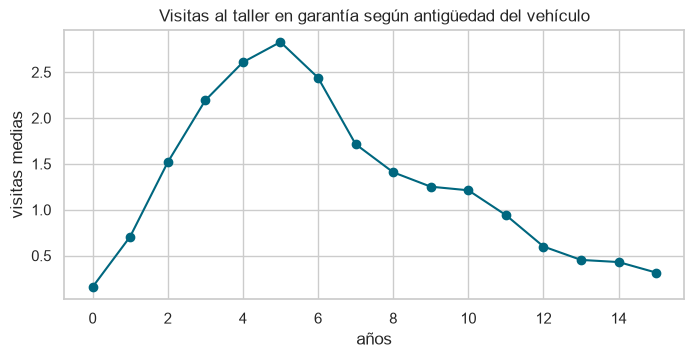

In [17]:
# Las visitas al taller dependen de la edad del coche: solo cuentan las de garantía / goodwill
edad_veh = (FECHA_REF - reg).dt.days / 365.25
ax = df.groupby(edad_veh.clip(upper=15).round())["workshop_visits_warranty_goodwill"].mean().plot(marker="o", color=AZUL, figsize=(8, 3.5))
ax.set(title="Visitas al taller en garantía según antigüedad del vehículo", xlabel="años", ylabel="visitas medias")
plt.show()

Las visitas crecen hasta ~5 años y después **bajan**: al terminar la garantía dejan de registrarse. Un coche nuevo
tiene pocas visitas porque no le ha dado tiempo, no porque su dueño cuide menos el coche. Hay que tenerlo en cuenta
al interpretar esta variable.

### Visitas al taller por país: diferencia de registro

In [18]:
cli_visitas = df.assign(antig=edad_veh).groupby("client_id").agg(visitas=("workshop_visits_warranty_goodwill", "mean"),
                                                                 pais=("country_code", "first"),
                                                                 antig=("antig", "median"))
tabla = pd.crosstab(cli_visitas["pais"], cli_visitas["visitas"].clip(upper=6).round(), normalize="index").mul(100)
tabla.columns = [f"{int(c)}{'+' if c == 6 else ''}" for c in tabla.columns]
tabla["antigüedad mediana del vehículo"] = cli_visitas.groupby("pais")["antig"].median()
tabla.round(1)

,0,1,2,3,4,5,6+,antigüedad mediana del vehículo
pais,,,,,,,,
AT,52.10,20.70,13.30,5.60,3.60,1.70,3.00,4.60
CH,22.60,15.70,19.70,13.20,10.90,6.10,11.80,4.90


Con coches de antigüedad similar, el **52 % de los clientes austriacos tiene 0 visitas** frente al 23 % de los
suizos. Es una diferencia de **registro** entre mercados más que de comportamiento. → En el Reto 2 las visitas se
expresan como percentil dentro del país.

## 5. Estadísticas descriptivas y distribuciones

In [19]:
num_cliente = ["months_as_mb_customer", "currently_connected_vehicles", "purchasing_power_per_inhabitant_eur",
               "purchasing_power_per_household_eur", "population", "number_of_households", "purchasing_power_millions_eur"]
desc = clientes[num_cliente].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["asimetría"] = clientes[num_cliente].skew()
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetría
months_as_mb_customer,"173,454.00",33.90,20.73,0.00,1.00,18.00,36.00,47.00,67.00,120.00,0.40
currently_connected_vehicles,"173,456.00",1.04,0.88,0.00,0.00,1.00,1.00,1.00,2.00,21.00,10.80
purchasing_power_per_inhabitant_eur,"158,097.00","47,189.33","17,304.08","19,701.53","27,169.71","32,072.80","46,753.32","54,750.58","77,483.13","148,353.74",1.68
purchasing_power_per_household_eur,"158,097.00","106,347.13","41,929.36","45,087.34","58,381.26","72,810.07","103,738.42","123,410.83","184,202.62","342,497.95",1.67
population,"158,140.00","20,066.46","37,090.01",0.00,"1,011.00","3,132.00","7,364.00","18,501.00","101,714.00","220,794.00",3.63
number_of_households,"158,140.00","9,531.86","17,902.72",0.00,432.00,"1,336.00","3,278.00","8,920.00","50,850.00","102,998.00",3.47
purchasing_power_millions_eur,"158,097.00",756.28,"1,045.49",0.65,41.71,140.43,347.92,943.57,"2,904.52","5,998.91",2.73


In [20]:
num_rel = ["workshop_visits_warranty_goodwill", "trip_distance_average", "operating_hours_total",
           "fuel_consumption_average", "speed_average"]
desc_rel = df[num_rel].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc_rel["asimetría"] = df[num_rel].skew()
desc_rel

,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetría
workshop_visits_warranty_goodwill,"302,850.00",1.75,2.43,0.00,0.00,0.00,1.00,3.00,7.00,44.00,2.19
trip_distance_average,"116,993.00",16.16,10.67,1.00,5.93,10.15,14.02,19.53,32.96,300.00,7.62
operating_hours_total,"128,492.00",620.27,742.61,0.00,7.64,137.48,406.51,855.95,"1,885.39","26,842.00",4.06
fuel_consumption_average,"122,125.00",8.56,3.26,3.00,5.07,6.58,8.11,9.72,13.54,50.00,3.60
speed_average,"120,468.00",48.67,14.21,0.12,25.40,41.23,49.34,57.25,69.97,220.00,-0.30


Casi todas las variables numéricas son **asimétricas a la derecha** (asimetría > 1): la mediana describe mejor al
cliente típico que la media, y en el modelo hará falta transformarlas (log) o recortarlas.

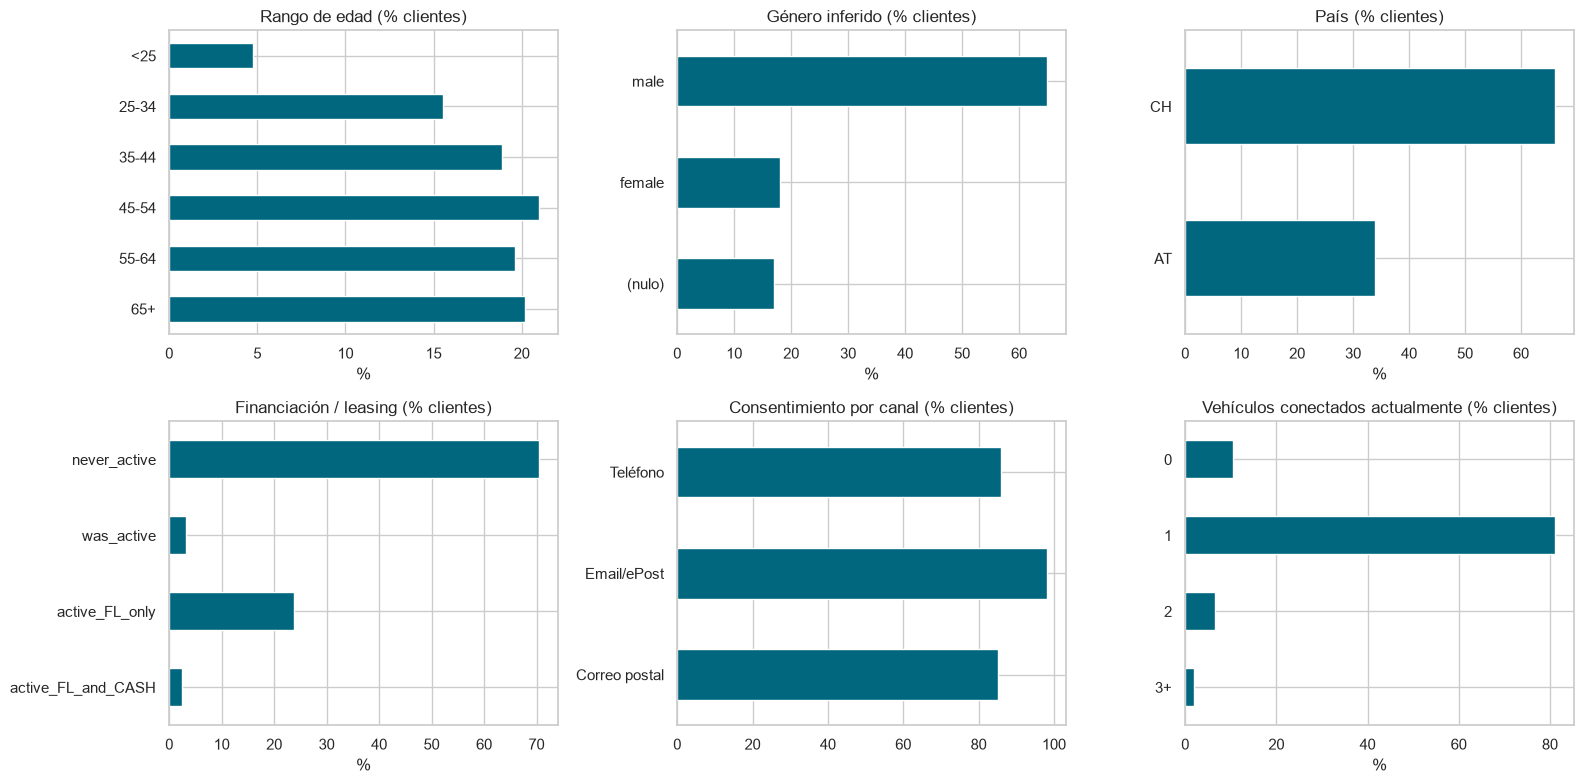

In [21]:
def barras(ax, s, titulo, orden=None, top=None):
    vc = s.fillna("(nulo)").value_counts(normalize=True).mul(100)
    vc = vc.reindex(orden) if orden else vc
    vc = vc.head(top) if top else vc
    vc.plot.barh(ax=ax, color=AZUL)
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel="%", ylabel="")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
barras(axes[0, 0], clientes["age_range"], "Rango de edad (% clientes)", orden=orden_edad)
barras(axes[0, 1], clientes["gender_derived"], "Género inferido (% clientes)")
barras(axes[0, 2], clientes["country_code"], "País (% clientes)")
barras(axes[1, 0], clientes["finance_leasing_status"], "Financiación / leasing (% clientes)",
       orden=["never_active", "was_active", "active_FL_only", "active_FL_and_CASH"])
consent = clientes[["consent_phone_communication_channel", "consent_epost_communication_channel",
                    "consent_post_communication_channel"]].mean().mul(100)
consent.index = ["Teléfono", "Email/ePost", "Correo postal"]
consent.plot.barh(ax=axes[1, 1], color=AZUL, title="Consentimiento por canal (% clientes)")
axes[1, 1].invert_yaxis()
barras(axes[1, 2], clientes["currently_connected_vehicles"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"}),
       "Vehículos conectados actualmente (% clientes)", orden=["0", "1", "2", "3+"])
plt.tight_layout()
plt.show()

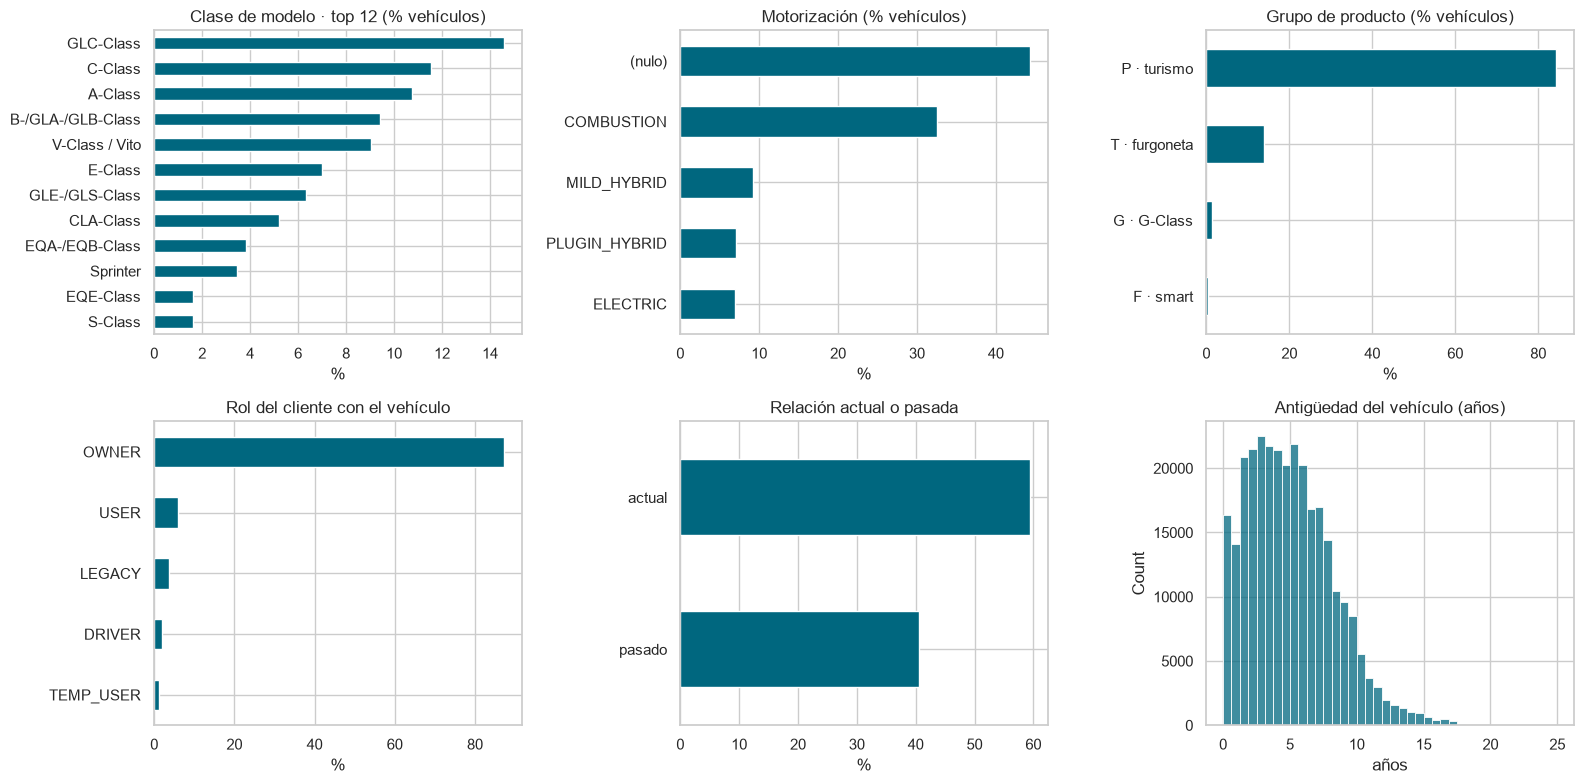

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
barras(axes[0, 0], df["model_class"], "Clase de modelo · top 12 (% vehículos)", top=12)
barras(axes[0, 1], df["engine_concept"], "Motorización (% vehículos)")
barras(axes[0, 2], df["product_group"].map({"P": "P · turismo", "T": "T · furgoneta", "G": "G · G-Class", "F": "F · smart"}),
       "Grupo de producto (% vehículos)")
barras(axes[1, 0], df["role"], "Rol del cliente con el vehículo")
barras(axes[1, 1], df["is_current_vehicle"].map({True: "actual", False: "pasado"}), "Relación actual o pasada")
sns.histplot(edad_veh.dropna(), bins=40, binrange=(0, 25), ax=axes[1, 2], color=AZUL)
axes[1, 2].set(title="Antigüedad del vehículo (años)", xlabel="años")
plt.tight_layout()
plt.show()

### Separando por país

Austria y Suiza son mercados distintos. Antes de agregar conclusiones, se comprueba qué variables cambian entre ellos.

In [23]:
cmp = pd.DataFrame({
    "edad 45+ (%)": clientes.groupby("country_code")["age_range"].apply(lambda s: s.isin(["45-54", "55-64", "65+"]).mean() * 100),
    "leasing activo (%)": clientes.groupby("country_code")["finance_leasing_status"].apply(lambda s: s.str.startswith("active").mean() * 100),
    "meses como cliente (mediana)": clientes.groupby("country_code")["months_as_mb_customer"].median(),
    "poder adquisitivo hogar (mediana, €)": clientes.groupby("country_code")[pp].median(),
    "electrificados (% vehículos con motor conocido)": df[df["engine_concept"].notna()].groupby("country_code")["engine_concept"].apply(lambda s: s.isin(["PLUGIN_HYBRID", "ELECTRIC"]).mean() * 100),
    "furgonetas (% vehículos)": df.groupby("country_code")["product_group"].apply(lambda s: (s == "T").mean() * 100),
    "visitas taller por vehículo (media)": df.groupby("country_code")["workshop_visits_warranty_goodwill"].mean(),
    "género desconocido (% clientes)": clientes.groupby("country_code")["gender_derived"].apply(lambda s: s.isna().mean() * 100),
}).T
cmp.round(1)

country_code,AT,CH
edad 45+ (%),63.20,59.60
leasing activo (%),15.60,31.60
meses como cliente (mediana),30.50,36.00
"poder adquisitivo hogar (mediana, €)","66,938.20","116,082.40"
electrificados (% vehículos con motor conocido),33.50,20.20
furgonetas (% vehículos),17.40,11.80
visitas taller por vehículo (media),1.00,2.20
género desconocido (% clientes),21.50,14.60


Diferencias relevantes entre países:
- **Poder adquisitivo**: CH casi duplica a AT. → En el modelo, siempre **relativo al país**.
- **Visitas al taller**: diferencia de registro (ver apartado 4). → Relativo al país.
- **Leasing** (más en CH) y **electrificación** (más en AT): diferencias de mercado reales, se mantienen.

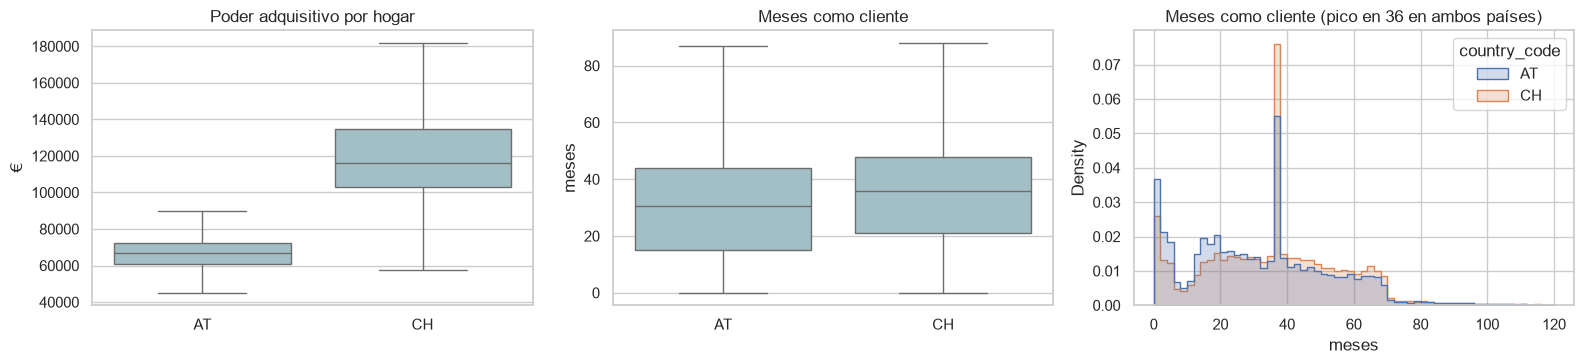

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.boxplot(data=clientes, x="country_code", y=pp, showfliers=False, ax=axes[0], color=AZUL_CLARO)
axes[0].set(title="Poder adquisitivo por hogar", xlabel="", ylabel="€")
sns.boxplot(data=clientes, x="country_code", y="months_as_mb_customer", showfliers=False, ax=axes[1], color=AZUL_CLARO)
axes[1].set(title="Meses como cliente", xlabel="", ylabel="meses")
sns.histplot(data=clientes, x="months_as_mb_customer", hue="country_code", bins=60, ax=axes[2], element="step", stat="density", common_norm=False)
axes[2].set(title="Meses como cliente (pico en 36 en ambos países)", xlabel="meses")
plt.tight_layout()
plt.show()

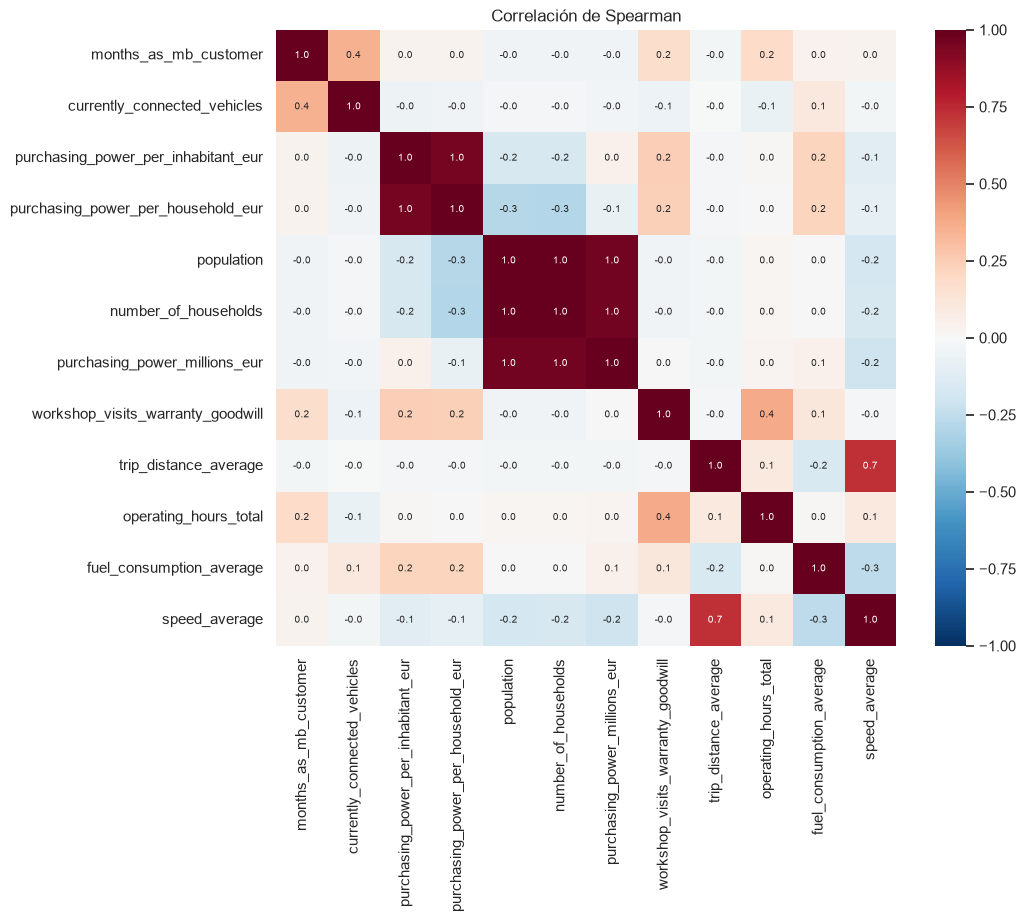

In [25]:
# Correlación (Spearman, robusta a asimetría y outliers) entre variables numéricas
corr = df[num_cliente + num_rel].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación de Spearman")
plt.show()

Las cinco variables socioeconómicas forman dos bloques casi redundantes: **poder adquisitivo por habitante ≈ por
hogar** y **población ≈ hogares ≈ poder total** (tamaño de la zona, no riqueza del cliente). → Se usa una sola:
poder adquisitivo por hogar.

## 6. Resumen de hallazgos

### ¿Cómo son los clientes?
- **173.456 clientes** de **Suiza (66 %)** y **Austria (34 %)**, con 302.850 relaciones con 244.519 vehículos.
- Perfil **maduro**: el 61 % tiene 45 años o más; los menores de 25 son menos del 5 %.
- Mayoría **masculina** (65 % hombre, 18 % mujer, 17 % sin dato; el género es inferido).
- Relación **reciente**: mediana de 36 meses como cliente, con un pico artificial en 36.
- Casi todos tienen **un vehículo conectado**. El 10 % no tiene ninguno: clientes **inactivos**.
- El 27 % ha tenido más de un Mercedes; ~1.700 clientes (1 %) tienen perfil de **flota** y acumulan el 20 % de las filas.
- Casi todo es **particular (B2C)**: el B2B es solo el 1,8 % de las relaciones.
- **Leasing**: el 29 % lo ha usado alguna vez, mucho más en Suiza.
- **Gama**: dominan los **turismos** (84 %), con GLC, C, A y E-Class a la cabeza. **1 de cada 4** vehículos con motor
  conocido es **electrificado**, más en Austria.
- El **email** está consentido por el 98 %: no diferencia. Teléfono y correo postal sí.

### Problemas de calidad y solución
| Problema | Solución |
|---|---|
| Granularidad cliente–vehículo y vehículos compartidos | Agregar a 1 fila por cliente; telemetría y taller como datos de la relación |
| Telemetría ausente de forma **estructural** (BEV, no propietarios, coches antiguos) | No imputar ni modelar; solo perfilar con advertencia |
| Motorización nula por sistema de origen | Deducción por nombre comercial + `UNKNOWN` |
| Género nulo concentrado en jóvenes y mayores | Categoría `unknown`; fuera del modelo |
| Socioeconómicos nulos y distintos por país | Mediana del país; variable relativa al país |
| Eliminar filas con nulos | Descartado: perdería el 18,6 % de clientes y sesgaría edad y país |
| Medianas/modas discretizadas y topes del sistema | Excluir medianas/modas; describir con medianas de las medias |
| Visitas al taller registradas distinto por país y ligadas a la garantía | Relativo al país; interpretar con la antigüedad del coche |
| Pico de 36 meses, CP mal formados, desajustes menores | Documentados; impacto acotado |
| Identificadores, metadatos y variables redundantes | Excluidos (apartado 2) |

In [26]:
resumen = {
    "clientes": n_clients,
    "relaciones cliente-vehículo": n_rows,
    "vehículos": n_vehicles,
    "% clientes CH": (clientes["country_code"] == "CH").mean() * 100,
    "% clientes hombres (inferido)": (clientes["gender_derived"] == "male").mean() * 100,
    "% clientes 45+": clientes["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
    "% clientes con >1 vehículo": (veh_por_cliente > 1).mean() * 100,
    "% clientes con financiación/leasing alguna vez": (clientes["finance_leasing_status"] != "never_active").mean() * 100,
    "% relaciones B2B": (df["role_type"] == "B2B").mean() * 100,
    "% vehículos electrificados (sobre motor conocido)": df["engine_concept"].isin(["PLUGIN_HYBRID", "ELECTRIC"]).sum() / df["engine_concept"].notna().sum() * 100,
    "% clientes sin vehículo conectado": (clientes["currently_connected_vehicles"] == 0).mean() * 100,
    "% clientes con consentimiento email": clientes["consent_epost_communication_channel"].mean() * 100,
    "% clientes que se perderían eliminando nulos": perdida * 100,
}
pd.Series(resumen).round(1)

clientes                                            173,456.00
relaciones cliente-vehículo                         302,850.00
vehículos                                           244,519.00
% clientes CH                                            66.20
% clientes hombres (inferido)                            65.00
% clientes 45+                                           60.80
% clientes con >1 vehículo                               26.70
% clientes con financiación/leasing alguna vez           29.40
% relaciones B2B                                          1.80
% vehículos electrificados (sobre motor conocido)        25.10
% clientes sin vehículo conectado                        10.40
% clientes con consentimiento email                      98.30
% clientes que se perderían eliminando nulos             18.60
dtype: float64